In [2]:
%pip install alpaca-py

Note: you may need to restart the kernel to use updated packages.


In [3]:
import os
from dotenv import load_dotenv
from alpaca.data.historical import StockHistoricalDataClient

load_dotenv()

API_KEY = os.getenv("API_KEY")
SECRET_KEY = os.getenv("SECRET_KEY")

client = StockHistoricalDataClient(API_KEY, SECRET_KEY)

In [4]:
from alpaca.data.requests import StockLatestTradeRequest
from alpaca.data.enums import DataFeed

request = StockLatestTradeRequest(
    symbol_or_symbols="AAPL",
    feed=DataFeed.IEX
)

trade = client.get_stock_latest_trade(request)["AAPL"]

print("Price:", trade.price)
print("Timestamp:", trade.timestamp)

Price: 343.39
Timestamp: 2026-10-16 19:59:58.574873+00:00


In [5]:
from alpaca.data.requests import StockBarsRequest
from alpaca.data.timeframe import TimeFrame
from alpaca.data.enums import DataFeed
from datetime import datetime, timedelta, timezone

ticker = "AAPL"

end = datetime.now(timezone.utc)
start = end - timedelta(days=30)

request = StockBarsRequest(
    symbol_or_symbols=ticker,
    timeframe=TimeFrame.Hour,
    start=start,
    end=end,
    feed=DataFeed.IEX
)

bars = client.get_stock_bars(request)

df = bars.df.reset_index()
display(df.head())

,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,AAPL,2026-09-21 12:00:00+00:00,336.350,336.35,336.120,336.120,264.0,9.0,336.238605
1,AAPL,2026-09-21 13:00:00+00:00,336.040,336.32,333.120,335.860,157917.0,2831.0,334.647985
2,AAPL,2026-09-21 14:00:00+00:00,335.855,338.18,335.710,337.010,151349.0,2947.0,337.003784
3,AAPL,2026-09-21 15:00:00+00:00,336.950,338.48,336.735,337.710,128389.0,3034.0,337.515390
4,AAPL,2026-09-21 16:00:00+00:00,337.580,339.25,337.540,338.725,102110.0,2578.0,338.660590


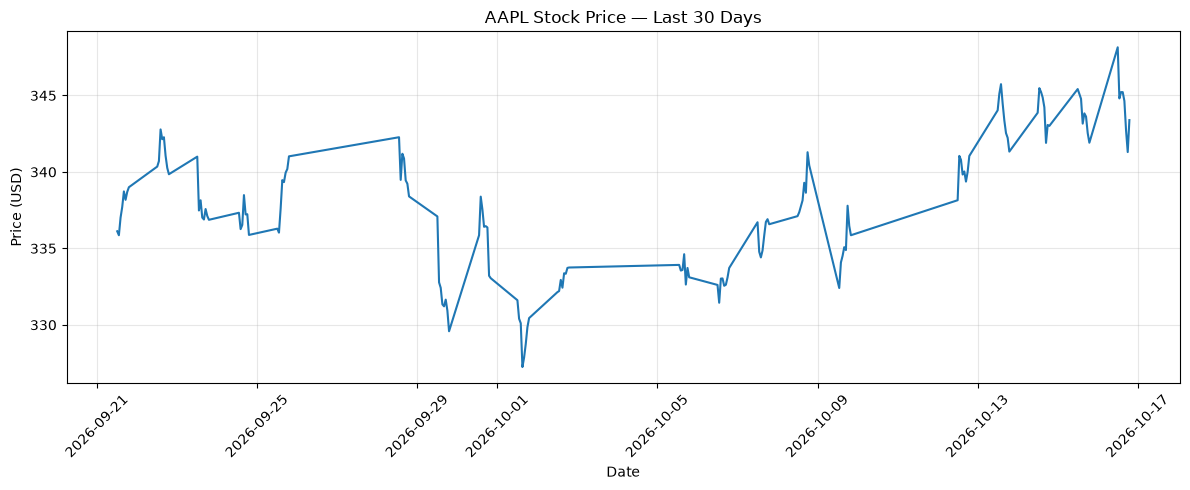

In [6]:
import matplotlib.pyplot as plt

df = df.sort_values("timestamp")

plt.figure(figsize=(12, 5))
plt.plot(df["timestamp"], df["close"])

plt.title(f"{ticker} Stock Price — Last 30 Days")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from alpaca.data.historical.news import NewsClient
from alpaca.data.requests import NewsRequest
from datetime import datetime
import pandas as pd

# pull corr recent news 
news_client = NewsClient(API_KEY, SECRET_KEY)


req = NewsRequest(
    symbols="AAPL",
    start=datetime(2026, 9, 17),
    end=datetime(2026, 10, 17),
    #limit =30
)

news = news_client.get_news(req)


In [14]:
print(req)

start=datetime.datetime(2026, 9, 17, 0, 0) end=datetime.datetime(2026, 10, 17, 0, 0) sort=None symbols='AAPL' limit=None include_content=None exclude_contentless=None page_token=None


In [12]:
# formatting check
news_df = pd.DataFrame([{
    "created_at": n.created_at,
    "headline": n.headline,
    "source": n.source,
    "symbols": n.symbols,
} for n in news.data["news"]])

print(news_df.shape)
print(news_df["created_at"].min(), news_df["created_at"].max())

(233, 4)
2026-09-17 07:14:14+00:00 2026-10-16 15:33:56+00:00


In [17]:
# check for ealier years data
news = news_client.get_news(req)

req = NewsRequest(
    symbols="AAPL",
    start=datetime(2020, 9, 17),
    end=datetime(2020, 10, 17),
)

news_df = pd.DataFrame([{
    "created_at": n.created_at,
    "headline": n.headline,
    "source": n.source,
    "symbols": n.symbols,
} for n in news.data["news"]])

print(news_df.shape)
print(news_df["created_at"].min(), news_df["created_at"].max())

(184, 4)
2020-09-17 08:01:55+00:00 2020-10-16 09:16:35+00:00
